In [1]:
!pip -q install kaggle

import os, glob, json, zipfile, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


In [2]:
# Upload kaggle.json
uploaded = files.upload()  # Select kaggle.json

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("Please upload your Kaggle API file named kaggle.json")

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

!kaggle datasets download -d emmarex/plantdisease -p /content/plant_data --unzip


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:06<00:00, 100MB/s]



In [3]:
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def count_images(folder):
    return sum(
        1 for p in glob.iglob(os.path.join(folder, "**", "*"), recursive=True)
        if os.path.isfile(p) and p.lower().endswith(IMAGE_EXTS)
    )

candidates = []
for root, dirs, filenames in os.walk("/content/plant_data"):
    class_dirs = [d for d in dirs if count_images(os.path.join(root, d)) > 0]
    if len(class_dirs) >= 2:
        candidates.append((len(class_dirs), count_images(root), root))

if not candidates:
    raise RuntimeError("Could not find class folders. Check that the dataset ZIP was extracted correctly.")

# Prefer the folder with the largest number of class folders, then most images.
DATA_DIR = sorted(candidates, reverse=True)[0][2]
print("Dataset folder:", DATA_DIR)
print("Number of classes:", len([d for d in os.listdir(DATA_DIR)
                                if os.path.isdir(os.path.join(DATA_DIR, d))]))
print("Total images:", count_images(DATA_DIR))

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)


Dataset folder: /content/plant_data/plantvillage/PlantVillage
Number of classes: 15
Total images: 20638
Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


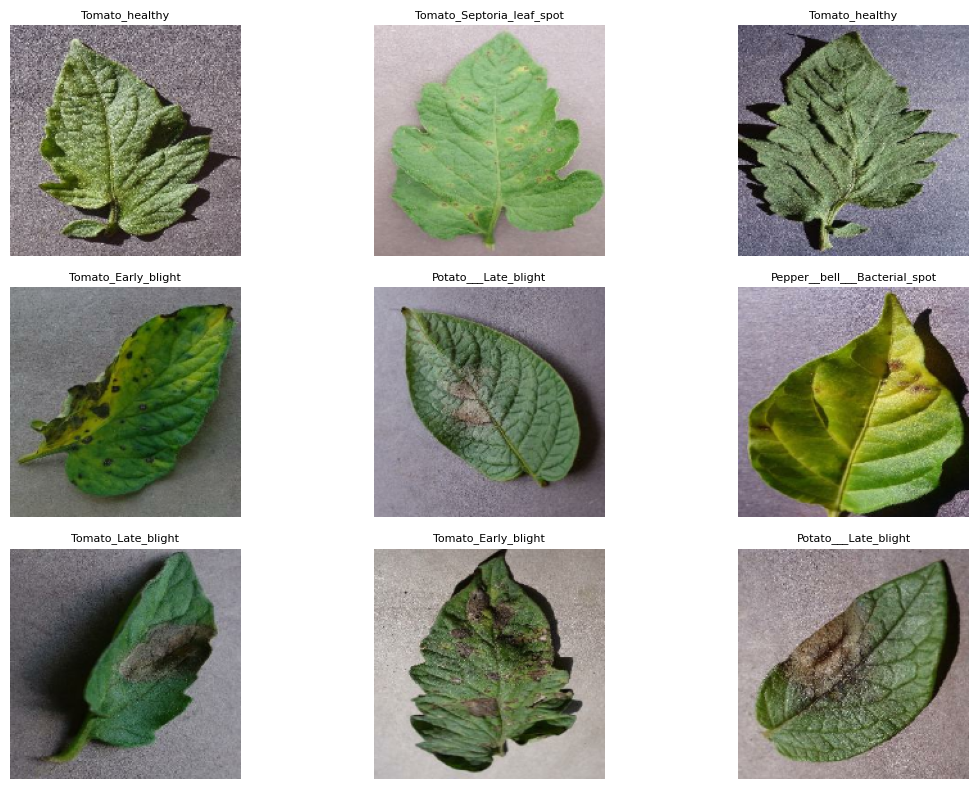

In [4]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,247 (1.61 MB)

 Trainable params: 423,247 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
EPOCHS = 10

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "best_plant_disease_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1532s 3s/step - accuracy: 0.3533 - loss: 1.9569 - val_accuracy: 0.5641 - val_loss: 1.3030
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1524s 3s/step - accuracy: 0.5929 - loss: 1.2261 - val_accuracy: 0.6605 - val_loss: 0.9772
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1532s 3s/step - accuracy: 0.7069 - loss: 0.8707 - val_accuracy: 0.7793 - val_loss: 0.6305
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1530s 3s/step - accuracy: 0.7674 - loss: 0.6855 - val_accuracy: 0.7407 - val_loss: 0.7802
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1483s 3s/step - accuracy: 0.8066 - loss: 0.5823 - val_accuracy: 0.8335 - val_loss: 0.4797
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1529s 3s/step - accuracy: 0.8302 - loss: 0.5012 - val_accuracy: 0.8384 - val_loss: 0.4738
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1530s 3s/step - accuracy: 0.8474 - loss: 0.4565 - val_accuracy: 0.8709 - val_loss: 0.3919
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 1528s 3s/step - accuracy: 0.8590 - loss: 0.4156 - 

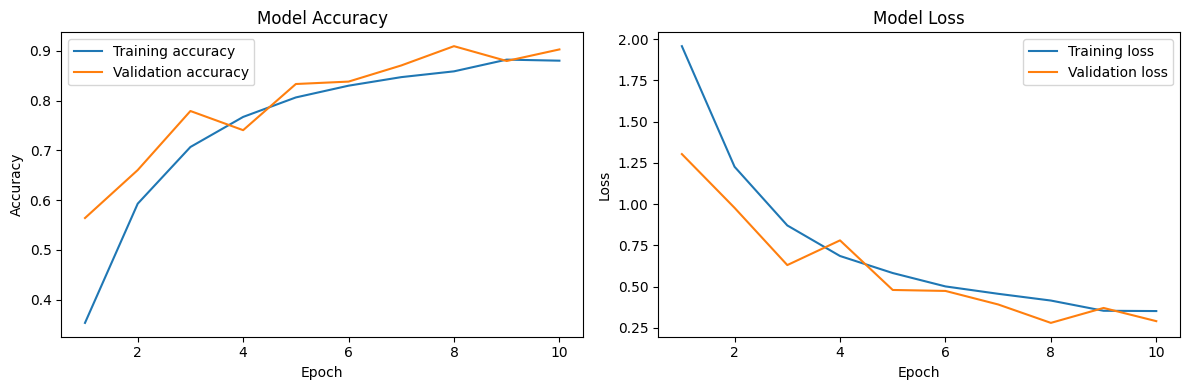

In [8]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training accuracy")
plt.plot(epochs_range, val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training loss")
plt.plot(epochs_range, val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
val_loss, val_accuracy = model.evaluate(val_ds)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation loss: {val_loss:.4f}")


129/129 ━━━━━━━━━━━━━━━━━━━━ 96s 740ms/step - accuracy: 0.9096 - loss: 0.2802
Validation accuracy: 90.96%
Validation loss: 0.2802


Saving WhatsApp Image 2026-11-27 at 2.01.47 PM.jpeg to WhatsApp Image 2026-11-27 at 2.01.47 PM.jpeg


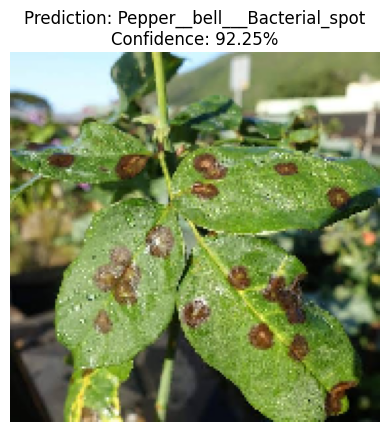

Predicted class: Pepper__bell___Bacterial_spot
Confidence: 92.25%


In [11]:
uploaded_leaf = files.upload()  # Upload a leaf image (JPG/PNG)
image_filename = next(
    name for name in uploaded_leaf
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
)

img = keras.utils.load_img(image_filename, target_size=IMG_SIZE)
img_array = keras.utils.img_to_array(img)
img_batch = tf.expand_dims(img_array, 0)

predictions = model.predict(img_batch, verbose=0)[0]
predicted_index = int(np.argmax(predictions))
confidence = float(predictions[predicted_index])

plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {class_names[predicted_index]}\nConfidence: {confidence*100:.2f}%")
plt.show()

print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {confidence*100:.2f}%")


In [12]:
top_indices = np.argsort(predictions)[::-1][:5]
for idx in top_indices:
    print(f"{class_names[idx]}: {predictions[idx] * 100:.2f}%")


Pepper__bell___Bacterial_spot: 92.25%
Tomato_Early_blight: 7.37%
Potato___Early_blight: 0.29%
Tomato_Septoria_leaf_spot: 0.08%
Tomato_Late_blight: 0.00%


In [13]:
model.save("plant_disease_detection_model.keras")
print("Model saved successfully.")

files.download("plant_disease_detection_model.keras")


Model saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>